# Partie 1

## Importation les bibliotheque

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Charger le dataset Titanic

In [41]:
df = pd.read_excel(r"titanicDataset.xls")

## afficher les cinq premier ligne 

In [42]:
df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


## Afficher les dimension

In [43]:
df.shape

(1309, 14)

## Afficher les type des donner

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   object 
 3   sex        1309 non-null   object 
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   object 
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    object 
 10  embarked   1307 non-null   object 
 11  boat       486 non-null    object 
 12  body       121 non-null    float64
 13  home.dest  745 non-null    object 
dtypes: float64(3), int64(4), object(7)
memory usage: 143.3+ KB


# Partie 2

## En divise le dataset

In [45]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["survived", "name", "ticket"])
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## Verifie les valeurs manquantes

In [46]:
print("Valeurs manquantes dans Train :")
print(X_train.isnull().sum())

print("\nValeurs manquantes dans Test :")
print(X_test.isnull().sum())

Valeurs manquantes dans Train :
pclass         0
sex            0
age          209
sibsp          0
parch          0
fare           1
cabin        822
embarked       0
boat         658
body         955
home.dest    450
dtype: int64

Valeurs manquantes dans Test :
pclass         0
sex            0
age           54
sibsp          0
parch          0
fare           0
cabin        192
embarked       2
boat         165
body         233
home.dest    114
dtype: int64


## Age

** Train

In [47]:
print("Nombre des valeur manquant avant: ",X_train["age"].isnull().sum())
X_train["age"] = X_train["age"].fillna(X_train["age"].median())
print("Nombre des valeur manquant apres: ",X_train["age"].isnull().sum())
print("le median: ",X_train["age"].median())


Nombre des valeur manquant avant:  209
Nombre des valeur manquant apres:  0
le median:  28.0


** Test

In [48]:
print("Nombre des valeur manquant avant: ",X_test["age"].isnull().sum())
X_test["age"] = X_test["age"].fillna(X_test["age"].median())
print("Nombre des valeur manquant apres: ",X_test["age"].isnull().sum())
print("le median: ",X_test["age"].median())


Nombre des valeur manquant avant:  54
Nombre des valeur manquant apres:  0
le median:  29.0


## Fare 

** Train

In [49]:
print("Nombre des valeur manquant avant: ",X_train["fare"].isnull().sum())
X_train["fare"] = X_train["fare"].fillna(X_train["fare"].median())
print("Nombre des valeur manquant apres: ",X_train["fare"].isnull().sum())
print("le median: ",X_train["fare"].median())


Nombre des valeur manquant avant:  1
Nombre des valeur manquant apres:  0
le median:  13.81665


** Test

In [50]:
print("Nombre des valeur manquant avant: ",X_test["fare"].isnull().sum())

Nombre des valeur manquant avant:  0


## Embarked

** Train

In [51]:
print("Nombre des valeur manquant avant: ",X_train["embarked"].isnull().sum())

Nombre des valeur manquant avant:  0


** Test

In [52]:
print("Nombre des valeur manquant avant: ",X_test["embarked"].isnull().sum())
X_test["embarked"] = X_test["embarked"].fillna(X_test["embarked"].mode()[0])
print("Nombre des valeur manquant apres: ",X_test["embarked"].isnull().sum())
print("le mode: ",X_test["embarked"].mode()[0]) 

Nombre des valeur manquant avant:  2
Nombre des valeur manquant apres:  0
le mode:  S


## Cabin

In [53]:
# j'ai calculer le porcentage si est depasse 40% en supprime la colonne

#Train
print("Nombre des valeur manquant avant: ",X_train["cabin"].isnull().sum())
print("Le porcentage est: ",X_train["cabin"].isnull().mean()*100)
if X_train["cabin"].isnull().mean() > 0.40 :
    X_train = X_train.drop(columns = ["cabin"])
    print(" ==>la colonne a ete supprimer.\n")
    

# Test
print("Nombre des valeur manquant avant: ",X_test["cabin"].isnull().sum())
print("Le porcentage est: ",X_test["cabin"].isnull().mean()*100)
if X_test["cabin"].isnull().mean() > 0.40 :
    X_test = X_test.drop(columns = ["cabin"])
    print(" ==>la colonne a ete supprimer.")


Nombre des valeur manquant avant:  822
Le porcentage est:  78.51002865329512
 ==>la colonne a ete supprimer.

Nombre des valeur manquant avant:  192
Le porcentage est:  73.2824427480916
 ==>la colonne a ete supprimer.


## boat

In [54]:
# Train

print("Nombre des valeur manquant avant: ",X_train["boat"].isna().sum())
print("Le porcentage est: ",X_train["boat"].isna().mean()*100)
if X_train["boat"].isna().mean() > 0.40 :
    X_train = X_train.drop(columns = ["boat"])
    print(" ==>la colonne a ete supprimer.\n")

# Test

print("Nombre des valeur manquant avant: ",X_test["boat"].isna().sum())
print("Le porcentage est: ",X_test["boat"].isna().mean()*100)
if X_test["boat"].isna().mean() > 0.40 :
    X_test = X_test.drop(columns = ["boat"])
    print(" ==>la colonne a ete supprimer.\n")

Nombre des valeur manquant avant:  658
Le porcentage est:  62.84622731614136
 ==>la colonne a ete supprimer.

Nombre des valeur manquant avant:  165
Le porcentage est:  62.97709923664122
 ==>la colonne a ete supprimer.



## Body

In [55]:
#Train

print("Nombre des valeur manquant avant: ",X_train["body"].isnull().sum())
print("Le porcentage est: ",X_train["body"].isnull().mean()*100)
if X_train["body"].isnull().mean() > 0.40 :
    X_train = X_train.drop(columns = ["body"])
    print(" ==>la colonne a ete supprimer.\n")

#Test 

print("Nombre des valeur manquant avant: ",X_test["body"].isnull().sum())
print("Le porcentage est: ",X_test["body"].isnull().mean()*100)
if X_test["body"].isnull().mean() > 0.40 :
    X_test = X_test.drop(columns = ["body"])
    print(" ==>la colonne a ete supprimer.")

Nombre des valeur manquant avant:  955
Le porcentage est:  91.21298949379178
 ==>la colonne a ete supprimer.

Nombre des valeur manquant avant:  233
Le porcentage est:  88.93129770992367
 ==>la colonne a ete supprimer.


## Home.dest

In [56]:
# Train 

print("Nombre des valeur manquant avant: ",X_train["home.dest"].isnull().sum())
print("Le porcentage est: ",X_train["home.dest"].isnull().mean()*100)
if X_train["home.dest"].isnull().mean() > 0.40 :
    X_train = X_train.drop(columns = ["home.dest"])
    print(" ==>la colonne a ete supprimer.\n")

# Test

print("Nombre des valeur manquant avant: ",X_test["home.dest"].isnull().sum())
print("Le porcentage est: ",X_test["home.dest"].isnull().mean()*100)
if X_test["home.dest"].isnull().mean() > 0.40 :
    X_test = X_test.drop(columns = ["home.dest"])
    print(" ==>la colonne a ete supprimer.\n")

Nombre des valeur manquant avant:  450
Le porcentage est:  42.97994269340974
 ==>la colonne a ete supprimer.

Nombre des valeur manquant avant:  114
Le porcentage est:  43.51145038167939
 ==>la colonne a ete supprimer.



## Test

In [57]:
print("Pour le training:\n",X_train.isnull().sum())
print("\nPour le test:\n",X_test.isnull().sum())

Pour le training:
 pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64

Pour le test:
 pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64


# detecter les valeur aberrantes 

## Age

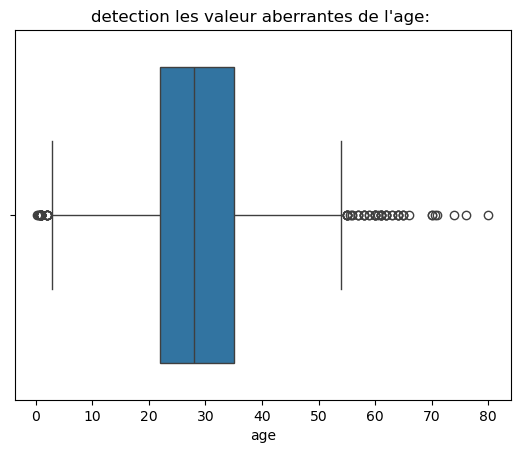

In [58]:
sns.boxplot(x=X_train["age"])
plt.title("detection les valeur aberrantes de l'age: ")
plt.show()

## Fare

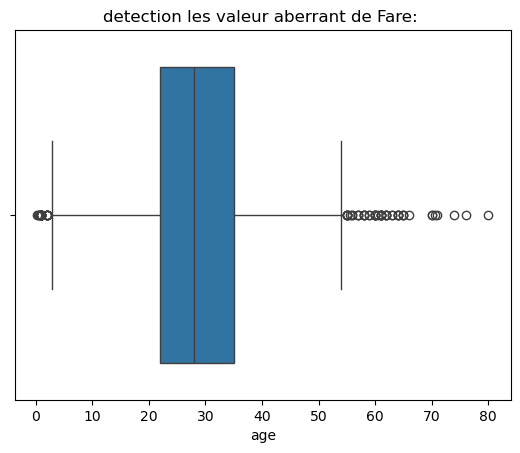

In [59]:
sns.boxplot(x = X_train["age"])
plt.title("detection les valeur aberrant de Fare: ")
plt.show()

# Remplacer les valeurs aberrant:

## age

In [60]:
Q1 = X_train["age"].quantile(0.25)
Q3 = X_train["age"].quantile(0.75)

IQR = Q3 - Q1
limite_inf = Q1 - 1.5 * IQR
limite_sup = Q3 + 1.5 * IQR

valeur_aberrante = X_train[ (X_train["age"] < limite_inf) | (X_train["age"] > limite_sup) ]
print("Limite inferieure:", limite_inf)
print("Limite superieure:", limite_sup)
print(" ==> Nombre des valeur aberrantes: ", len(valeur_aberrante))

Limite inferieure: 2.5
Limite superieure: 54.5
 ==> Nombre des valeur aberrantes:  77


In [61]:
mediane = X_train["age"].median()
print("le mediane de l'age est: ",mediane)
X_train.loc[
    (X_train["age"] < limite_inf) |
    (X_train["age"] > limite_sup),
    "age"
] = mediane

le mediane de l'age est:  28.0


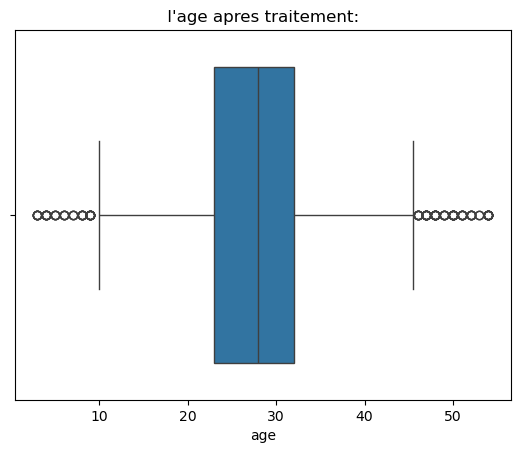

In [62]:
sns.boxplot(x=X_train["age"])
plt.title(" l'age apres traitement: ")
plt.show()

## fare

In [63]:
Q1 = X_train["fare"].quantile(0.25)
Q3 = X_train["fare"].quantile(0.75)

IQR = Q3 - Q1
limite_inf = Q1 - 1.5 * IQR
limite_sup = Q3 + 1.5 * IQR

valeur_aberrante = X_train[ (X_train["fare"] < limite_inf) | (X_train["fare"] > limite_sup) ]

print("Limite inferieure:", limite_inf)
print("Limite superieure:", limite_sup)
print(" ==> Nombre des valeur aberrantes: ", len(valeur_aberrante))

Limite inferieure: -26.532349999999994
Limite superieure: 65.27605
 ==> Nombre des valeur aberrantes:  133


In [64]:
mediane = X_train["fare"].median()

X_train.loc[
    (X_train["fare"] < limite_inf) |
    (X_train["fare"] > limite_sup),
    "fare"
] = mediane

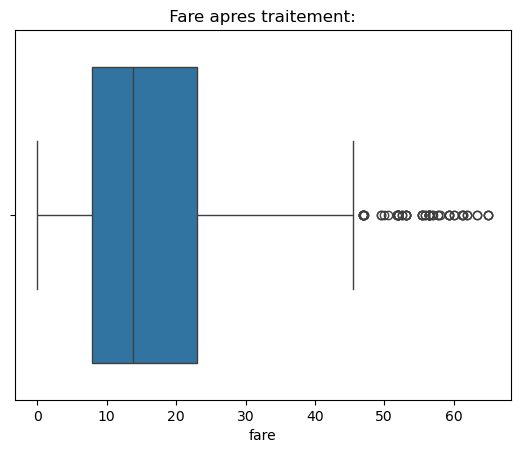

In [65]:
sns.boxplot(x=X_train["fare"])
plt.title(" Fare apres traitement: ")
plt.show()

# Partie 3

## Identifiez les colonnes avec des données catégorielles 

In [66]:
X_train.select_dtypes(include=["object", "category"]).head()

,sex,embarked
999,female,Q
392,female,C
628,female,S
1165,male,C
604,female,S


## Encodage des variables catégorielles :

In [67]:
X_train = pd.get_dummies(X_train, columns=["sex"], dtype=int)

In [68]:
X_train = pd.get_dummies(X_train, columns=["embarked"], dtype=int)

In [69]:
X_train.head()

,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
999,3,28.0,0,0,7.7500,1,0,0,1,0
392,2,24.0,1,0,27.7208,1,0,1,0,0
628,3,11.0,4,2,31.2750,1,0,0,0,1
1165,3,25.0,0,0,7.2250,0,1,1,0,0
604,3,16.0,0,0,7.6500,1,0,0,0,1


la colonne Pclass contient déjà des valeurs numériques (1, 2 et 3).

Donc, nous n'avons pas besoin de la transformer.

## Normalisation des données (Min-Max Scaling)

In [70]:
from sklearn.preprocessing import MinMaxScaler

scaler_minmax = MinMaxScaler()
X_train_norm = X_train.copy()
X_test_norm = X_test.copy()
colonnes_num = ["pclass", "age", "sibsp", "parch", "fare"]

X_train_norm[colonnes_num] = scaler_minmax.fit_transform(X_train[colonnes_num])

X_test_norm[colonnes_num] = scaler_minmax.transform(X_test[colonnes_num])
X_train_norm.head()

,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
999,1.0,0.490196,0.000,0.000000,0.119231,1,0,0,1,0
392,0.5,0.411765,0.125,0.000000,0.426474,1,0,1,0,0
628,1.0,0.156863,0.500,0.222222,0.481154,1,0,0,0,1
1165,1.0,0.431373,0.000,0.000000,0.111154,0,1,1,0,0
604,1.0,0.254902,0.000,0.000000,0.117692,1,0,0,0,1


## Standardisation des donnees(Z-score)

In [71]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_std = X_train.copy()
X_test_std = X_test.copy()

X_train_std[colonnes_num] = scaler.fit_transform(X_train[colonnes_num])
X_test_std[colonnes_num] = scaler.transform(X_test[colonnes_num])

X_train_std[colonnes_num].describe()

,pclass,age,sibsp,parch,fare
count,1.047000e+03,1.047000e+03,1.047000e+03,1.047000e+03,1.047000e+03
mean,1.509988e-16,-1.085834e-16,-6.786464e-18,-5.089848e-18,-1.976558e-16
std,1.000478e+00,1.000478e+00,1.000478e+00,1.000478e+00,1.000478e+00
min,-1.580849e+00,-2.637899e+00,-4.795708e-01,-4.475971e-01,-1.332732e+00
25%,-3.779792e-01,-5.578958e-01,-4.795708e-01,-4.475971e-01,-7.194013e-01
50%,8.248908e-01,-3.789500e-02,-4.795708e-01,-4.475971e-01,-2.594807e-01
75%,8.248908e-01,3.781056e-01,5.107854e-01,-4.475971e-01,4.538649e-01
max,8.248908e-01,2.666109e+00,7.443279e+00,9.992274e+00,3.716347e+00


## Comparez les distributions par histogramme 

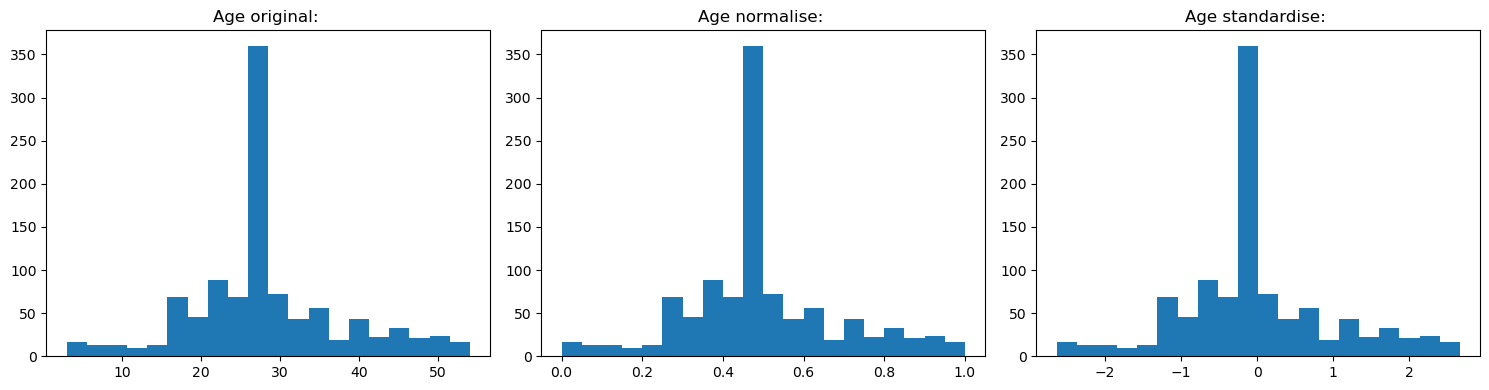

In [72]:
plt.figure(figsize=(15, 4))

# Données originales
plt.subplot(1, 3, 1)
plt.hist(X_train["age"], bins=20)
plt.title("Age original: ")

# Données normalisées
plt.subplot(1, 3, 2)
plt.hist(X_train_norm["age"], bins=20)
plt.title("Age normalise: ")

# Données standardisées
plt.subplot(1, 3, 3)
plt.hist(X_train_std["age"], bins=20)
plt.title("Age standardise: ")

plt.tight_layout()
plt.show()

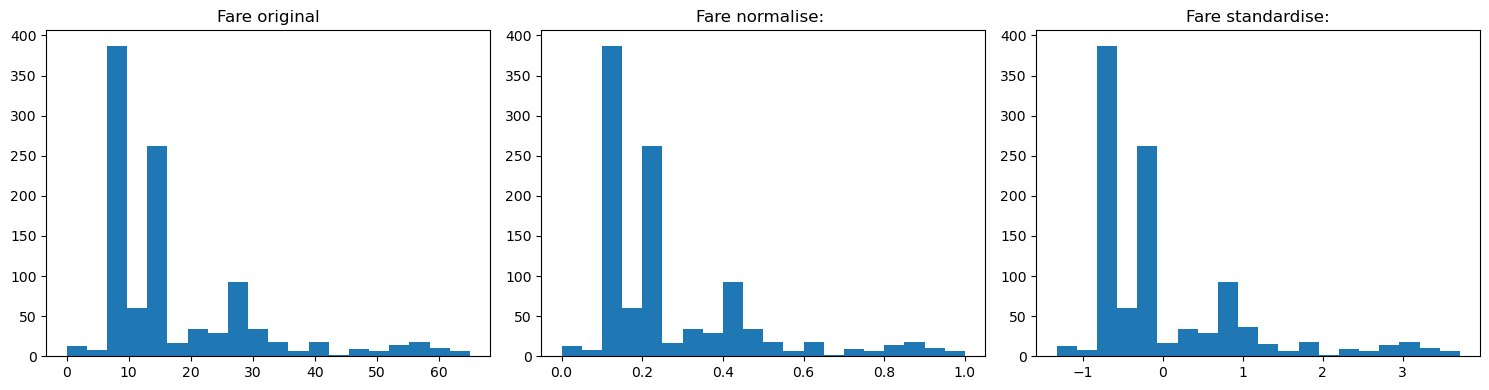

In [73]:
plt.figure(figsize=(15, 4))

# Données originales
plt.subplot(1, 3, 1)
plt.hist(X_train["fare"], bins=20)
plt.title("Fare original")

# Données normalisées
plt.subplot(1, 3, 2)
plt.hist(X_train_norm["fare"], bins=20)
plt.title("Fare normalise: ")

# Données standardisées
plt.subplot(1, 3, 3)
plt.hist(X_train_std["fare"], bins=20)
plt.title("Fare standardise:")

plt.tight_layout()
plt.show()

# Partie 4

## Gestion des Données Déséquilibrées

In [74]:
y_train.value_counts()

survived
0    647
1    400
Name: count, dtype: int64

In [75]:
# les pourcentage
print(y_train.value_counts(normalize=True) * 100)

survived
0    61.795606
1    38.204394
Name: proportion, dtype: float64


## Sous-échantillonnage

In [76]:
from imblearn.under_sampling import RandomUnderSampler
under = RandomUnderSampler(random_state=42)
X_under, y_under = under.fit_resample(X_train, y_train)
print("Apres undersampling :")
print(y_under.value_counts())

Apres undersampling :
survived
0    400
1    400
Name: count, dtype: int64


## sur-échantillonnage avec SMOTE (Oversampling)

In [77]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_smote, y_smote = smote.fit_resample(X_train, y_train)
print("Apres SMOTE :")
print(y_smote.value_counts())

Apres SMOTE :
survived
1    647
0    647
Name: count, dtype: int64
